In [9]:
# Implementation: Comparing a modified CUSUM with the standard CUSUM

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

In [12]:
class CUSUMCompare:
    """
    Compare standard vs. modified non-Bayesian CUSUM recursions:
      W_std[n] = max(0, W_std[n-1] + llr)
      W_mod[n] = max(0, W_mod[n-1])   + llr
    """

    def __init__(self, f0_pdf, f1_pdf, threshold):
        self.f0 = f0_pdf
        self.f1 = f1_pdf
        self.b = threshold

    def run(self, x):
        x = np.asarray(x)
        W_std = np.zeros_like(x, dtype=float)
        W_mod = np.zeros_like(x, dtype=float)
        tau_std = None
        tau_mod = None

        for n in range(1, len(x)):
            llr = np.log(self.f1(x[n]) / self.f0(x[n]))

            # standard CUSUM recursion
            W_std[n] = max(0, W_std[n-1] + llr)
            if tau_std is None and W_std[n] >= self.b:
                tau_std = n

            # modified CUSUM recursion (exact minimax opt.)
            W_mod[n] = max(0, W_mod[n-1]) + llr
            if tau_mod is None and W_mod[n] >= self.b:
                tau_mod = n

        return W_std, W_mod, tau_std, tau_mod


if __name__ == "__main__":
    # simulate pre- and post-change data
    np.random.seed(113)
    n_pre, n_post = 100, 200
    mu0, mu1, sigma = 0, 0.2, 1
    x = np.concatenate([
        np.random.normal(mu0, sigma, n_pre),
        np.random.normal(mu1, sigma, n_post)
    ])

    f0 = lambda x: norm.pdf(x, mu0, sigma)
    f1 = lambda x: norm.pdf(x, mu1, sigma)
    threshold = 5.0

    detector = CUSUMCompare(f0, f1, threshold)
    W_std, W_mod, tau_std, tau_mod = detector.run(x)

    print(f"True change at n={n_pre}")
    print(f"Standard CUSUM detected at τ_std = {tau_std}")
    print(f"Modified CUSUM detected at τ_mod = {tau_mod}")

  


True change at n=100
Standard CUSUM detected at τ_std = 175
Modified CUSUM detected at τ_mod = 175


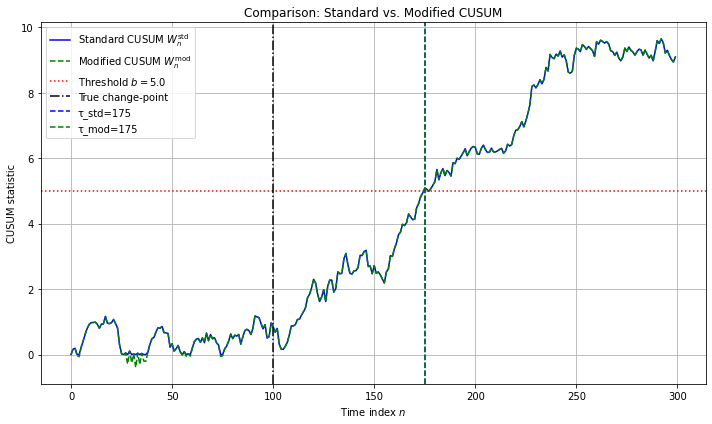

In [13]:
  # Plot both statistics
    plt.figure(figsize=(10, 6))
    plt.plot(W_std, label='Standard CUSUM $W^{\\mathrm{std}}_n$', color='blue')
    plt.plot(W_mod, label='Modified CUSUM $W^{\\mathrm{mod}}_n$', color='green', linestyle='--')
    plt.axhline(threshold, color='red', linestyle=':', label=f'Threshold $b={threshold}$')
    plt.axvline(n_pre, color='k', linestyle='-.', label='True change-point')
    if tau_std is not None:
        plt.axvline(tau_std, color='blue', linestyle='--', label=f'τ_std={tau_std}')
    if tau_mod is not None:
        plt.axvline(tau_mod, color='green', linestyle='--', label=f'τ_mod={tau_mod}')
    plt.xlabel('Time index $n$')
    plt.ylabel('CUSUM statistic')
    plt.title('Comparison: Standard vs. Modified CUSUM')
    plt.legend(loc='upper left')
    plt.grid(True)
    plt.tight_layout()
    plt.show()